# Financial Market Regimes Analysis

**Topic:** F9 – Régimes de marché  
**Task:** Unsupervised learning / clustering

The objective of this project is to identify different financial market regimes using historical market data and unsupervised machine learning techniques. We will calculate financial indicators and group market observations according to their characteristics.

## 1. Importation des bibliothèques

In [55]:
!pip -q install yfinance

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 5)

## 2. Téléchargement des données financières

In [56]:
# S&P 500 daily historical data
ticker = "^GSPC"

data = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-11-17",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError(
        "Aucune donnée n'a été téléchargée. Vérifiez la connexion Internet "
        "de Colab ou réessayez plus tard."
    )

# yfinance may return MultiIndex columns depending on its version
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

required_columns = ["Close", "Volume"]
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Colonnes absentes dans les données : {missing_columns}")

data = data[required_columns].copy()
data = data.sort_index()
data = data[~data.index.duplicated(keep="first")]

print("Dimensions du dataset :", data.shape)
print("Période :", data.index.min().date(), "à", data.index.max().date())
display(data.head())

Dimensions du dataset : (2986, 2)
Période : 2015-01-02 à 2026-11-16


Price,Close,Volume
Date,,
2015-01-02,2058.199951,2708700000
2015-01-05,2020.579956,3799120000
2015-01-06,2002.609985,4460110000
2015-01-07,2025.900024,3805480000
2015-01-08,2062.139893,3934010000


## 3. Exploration des données

In [57]:
print("Informations générales :")
data.info()

print("\nValeurs manquantes :")
display(data.isnull().sum().to_frame("Nombre de valeurs manquantes"))

print("\nStatistiques descriptives :")
display(data.describe())

Informations générales :
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2986 entries, 2015-01-02 to 2026-11-16
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2986 non-null   float64
 1   Volume  2986 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 70.0 KB

Valeurs manquantes :


,Nombre de valeurs manquantes
Price,
Close,0
Volume,0



Statistiques descriptives :


Price,Close,Volume
count,2986.000000,2.986000e+03
mean,3886.587522,4.204600e+09
std,1603.671267,1.057166e+09
min,1829.079956,0.000000e+00
25%,2581.017517,3.502222e+09
50%,3636.880005,3.967435e+09
75%,4701.132446,4.721582e+09
max,7818.930176,1.002582e+10


## 4. Visualisation 1 – Évolution du S&P 500

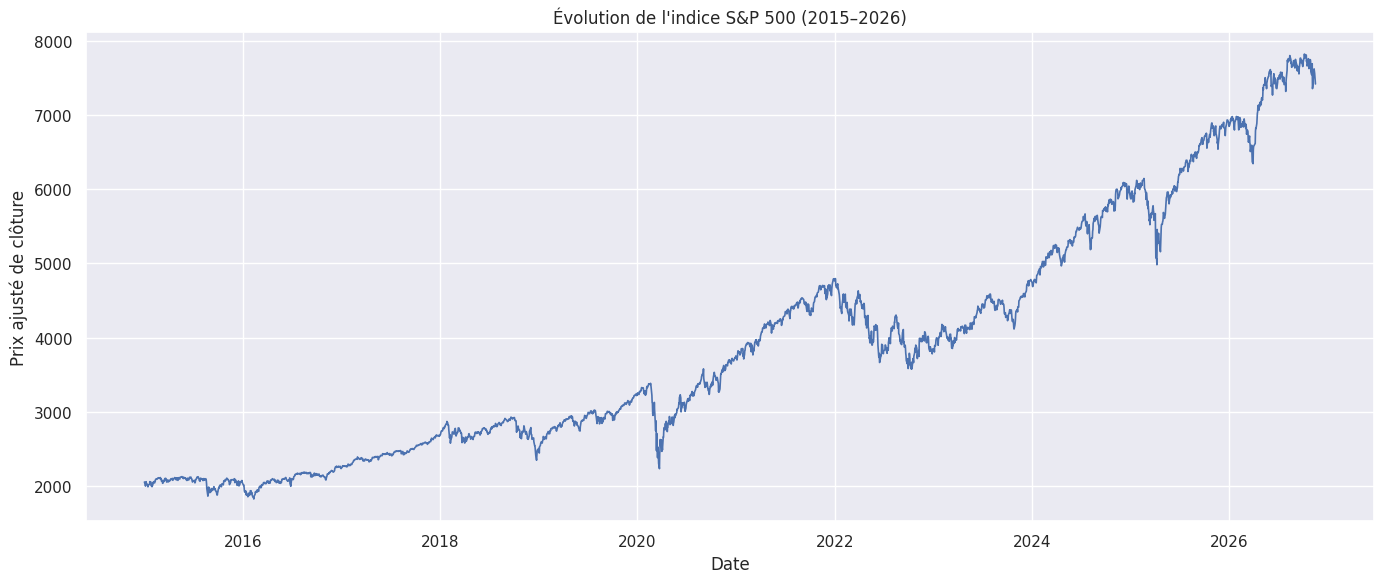

In [58]:
plt.figure(figsize=(14, 6))
plt.plot(data.index, data["Close"], linewidth=1.2)
plt.title("Évolution de l'indice S&P 500 (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Prix ajusté de clôture")
plt.tight_layout()
plt.show()

Le graphique présente l'évolution historique de l'indice S&P 500. Les variations du niveau de l'indice permettent de repérer les grandes phases de hausse et de baisse du marché.

## 5. Création des indicateurs financiers

In [59]:
# Rendement journalier
data["Return"] = data["Close"].pct_change()

# Volatilité historique sur 20 séances
data["Volatility"] = data["Return"].rolling(window=20).std()

# Momentum sur 20 séances
data["Momentum"] = data["Close"].pct_change(periods=20)

# Drawdown par rapport au maximum des 20 dernières séances
rolling_max = data["Close"].rolling(window=20).max()
data["Drawdown"] = data["Close"] / rolling_max - 1

# Nettoyage des lignes générées par les fenêtres glissantes
data = data.replace([np.inf, -np.inf], np.nan).dropna()

display(data[["Close", "Return", "Volatility", "Momentum", "Drawdown"]].head())
print("Dimensions après création des indicateurs :", data.shape)

Price,Close,Return,Volatility,Momentum,Drawdown
Date,,,,,
2015-02-02,2020.849976,0.012962,0.011192,-0.018147,-0.020503
2015-02-03,2050.030029,0.014439,0.010899,0.014575,-0.006359
2015-02-04,2041.510010,-0.004156,0.010727,0.019425,-0.010489
2015-02-05,2062.520020,0.010291,0.010662,0.018076,-0.000305
2015-02-06,2055.469971,-0.003418,0.009919,-0.003234,-0.003722


Dimensions après création des indicateurs : (2966, 6)


## 6. Visualisation 2 – Rendements et volatilité

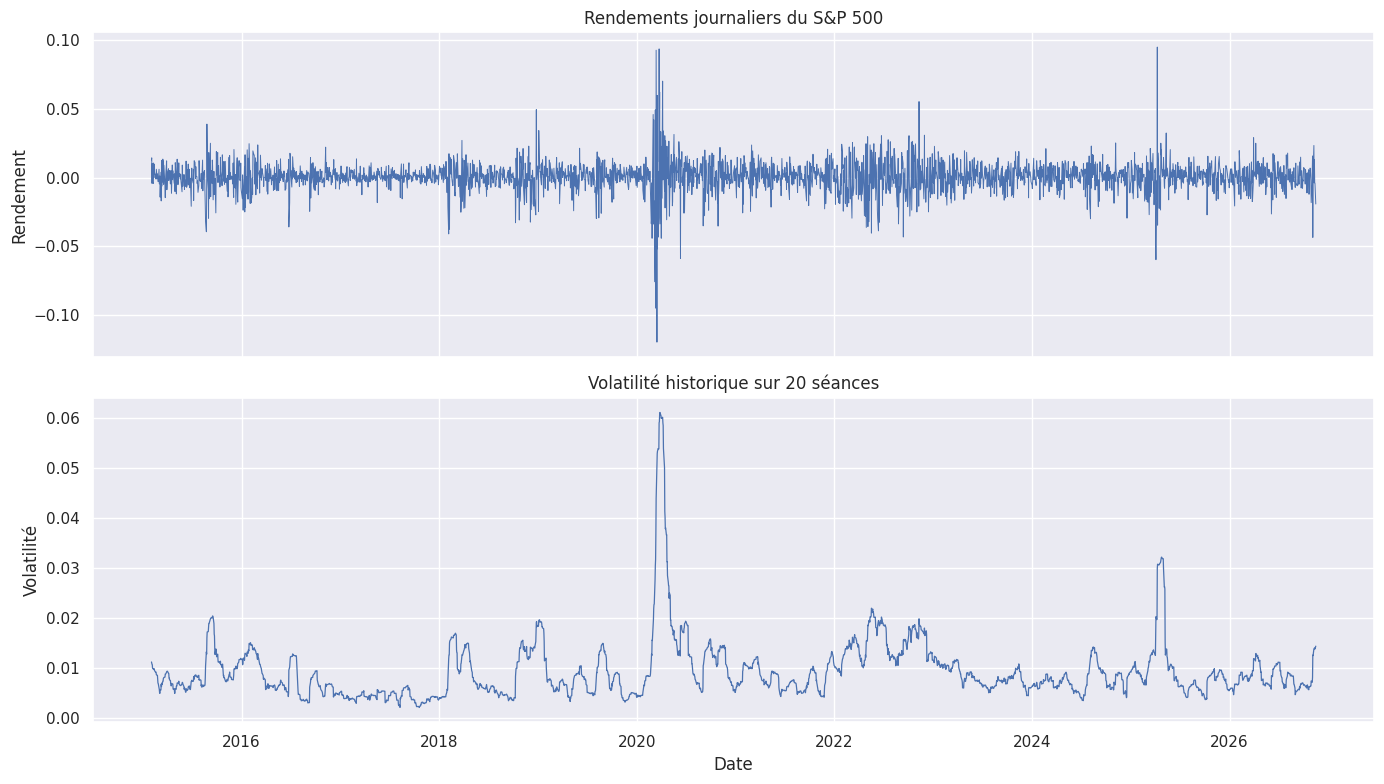

In [60]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(data.index, data["Return"], linewidth=0.7)
axes[0].set_title("Rendements journaliers du S&P 500")
axes[0].set_ylabel("Rendement")

axes[1].plot(data.index, data["Volatility"], linewidth=0.9)
axes[1].set_title("Volatilité historique sur 20 séances")
axes[1].set_ylabel("Volatilité")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

La volatilité mesure l'intensité des fluctuations des rendements. Une volatilité élevée indique un marché plus agité, tandis qu'une volatilité faible correspond à des variations plus limitées.

## 7. Visualisation 3 – Momentum et drawdown

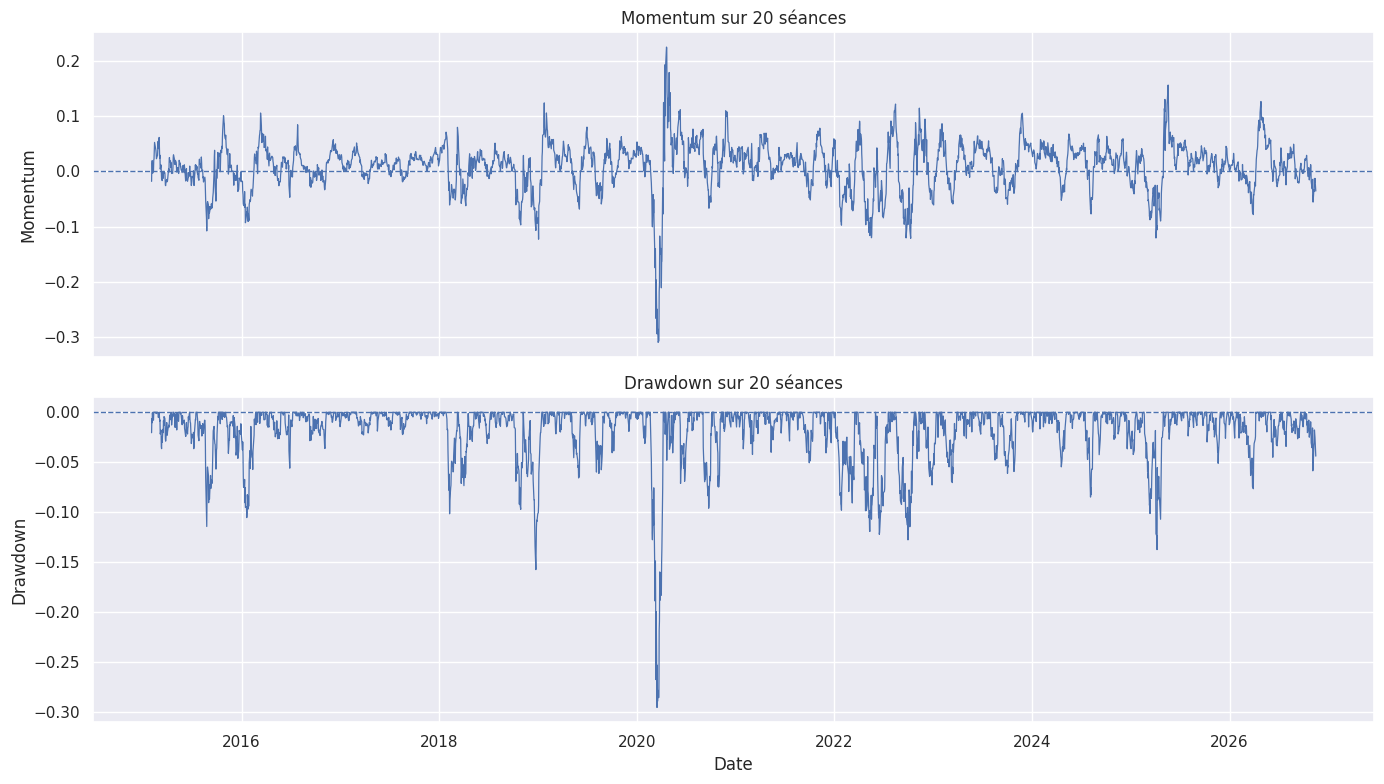

In [61]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(data.index, data["Momentum"], linewidth=0.9)
axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_title("Momentum sur 20 séances")
axes[0].set_ylabel("Momentum")

axes[1].plot(data.index, data["Drawdown"], linewidth=0.9)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("Drawdown sur 20 séances")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

Le momentum mesure la direction récente du marché : une valeur positive indique une progression sur la période considérée, et une valeur négative indique un recul.

Le drawdown mesure la baisse du prix par rapport au maximum récent. Des valeurs plus négatives signalent une baisse plus importante.

## 8. Préparation des variables pour le clustering

In [62]:
features = ["Return", "Volatility", "Momentum", "Drawdown"]
X = data[features].copy()

print("Variables retenues :", features)
print("Dimensions :", X.shape)
display(X.head())

Variables retenues : ['Return', 'Volatility', 'Momentum', 'Drawdown']
Dimensions : (2966, 4)


Price,Return,Volatility,Momentum,Drawdown
Date,,,,
2015-02-02,0.012962,0.011192,-0.018147,-0.020503
2015-02-03,0.014439,0.010899,0.014575,-0.006359
2015-02-04,-0.004156,0.010727,0.019425,-0.010489
2015-02-05,0.010291,0.010662,0.018076,-0.000305
2015-02-06,-0.003418,0.009919,-0.003234,-0.003722


## 9. Séparation chronologique des données

In [63]:
# Les observations les plus récentes sont conservées pour le test.
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

print("Période d'entraînement :", X_train.index.min().date(), "à", X_train.index.max().date())
print("Période de test :", X_test.index.min().date(), "à", X_test.index.max().date())
print("Taille entraînement :", X_train.shape)
print("Taille test :", X_test.shape)

Période d'entraînement : 2015-02-02 à 2024-07-05
Période de test : 2024-07-08 à 2026-11-16
Taille entraînement : (2372, 4)
Taille test : (594, 4)


## 10. Standardisation des variables

In [64]:
# Le scaler est ajusté uniquement sur la période d'entraînement.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Standardisation terminée.")

Standardisation terminée.


## 11. Algorithme 1 – K-Means : choix du nombre de clusters

In [65]:
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_train_scaled)

    score = silhouette_score(
        X_train_scaled,
        labels,
        sample_size=min(5000, len(X_train_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)
    print(f"k = {k} | Silhouette Score = {score:.4f}")

k = 2 | Silhouette Score = 0.5331
k = 3 | Silhouette Score = 0.4782
k = 4 | Silhouette Score = 0.4334
k = 5 | Silhouette Score = 0.3307
k = 6 | Silhouette Score = 0.3344


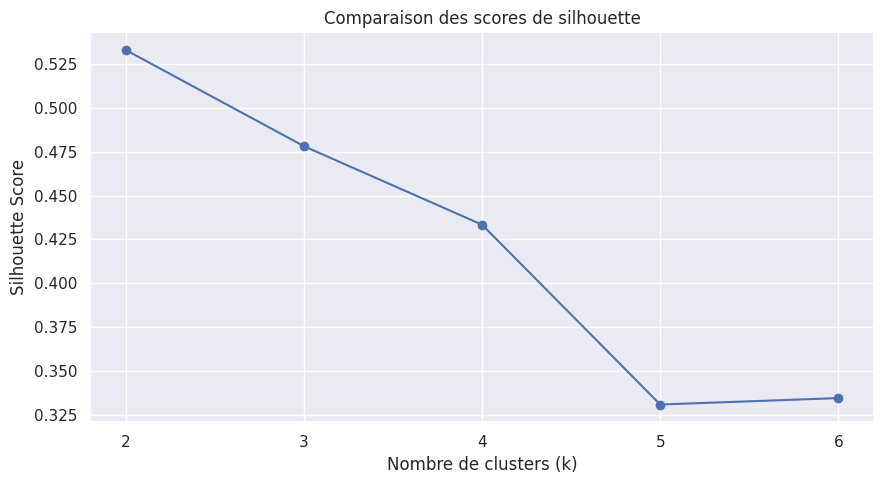

Nombre de clusters retenu : 2


In [66]:
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Comparaison des scores de silhouette")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print("Nombre de clusters retenu :", best_k)

## 12. Entraînement de K-Means et affectation des régimes

In [67]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)

train_labels = kmeans.predict(X_train_scaled)
test_labels = kmeans.predict(X_test_scaled)

data["Regime"] = np.concatenate([train_labels, test_labels])

print("Clustering terminé.")
display(data[["Close", "Return", "Volatility", "Momentum", "Drawdown", "Regime"]].head())

Clustering terminé.


Price,Close,Return,Volatility,Momentum,Drawdown,Regime
Date,,,,,,
2015-02-02,2020.849976,0.012962,0.011192,-0.018147,-0.020503,1
2015-02-03,2050.030029,0.014439,0.010899,0.014575,-0.006359,1
2015-02-04,2041.510010,-0.004156,0.010727,0.019425,-0.010489,1
2015-02-05,2062.520020,0.010291,0.010662,0.018076,-0.000305,1
2015-02-06,2055.469971,-0.003418,0.009919,-0.003234,-0.003722,1


## 13. Visualisation des régimes identifiés

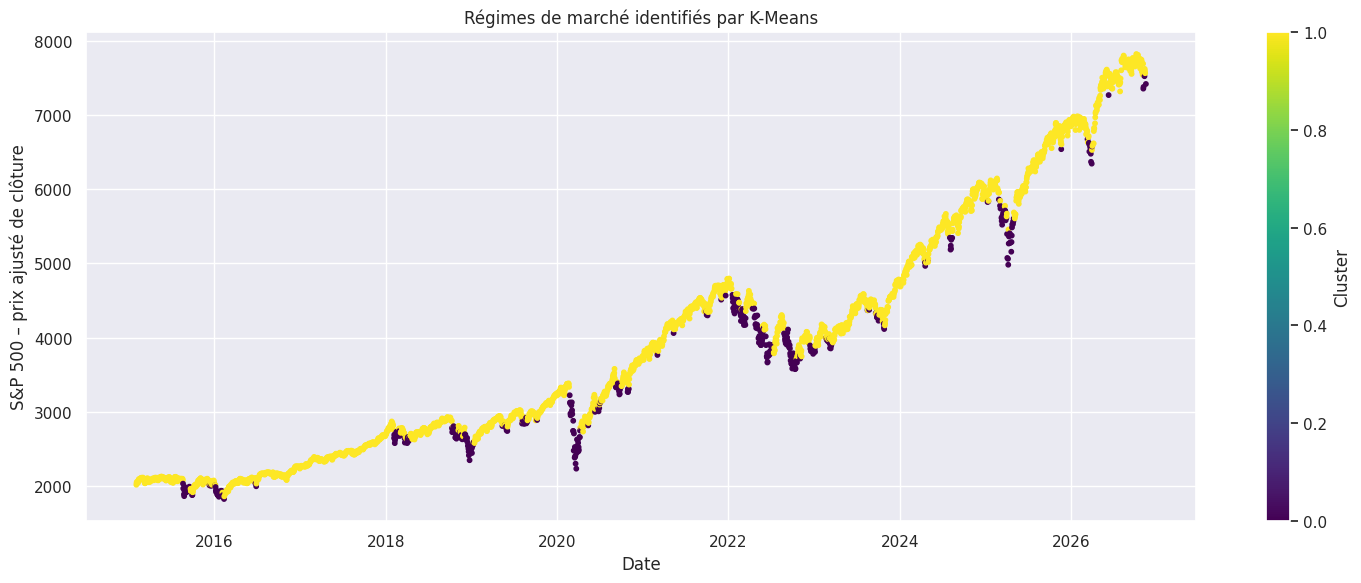

In [68]:
plt.figure(figsize=(15, 6))
scatter = plt.scatter(
    data.index,
    data["Close"],
    c=data["Regime"],
    cmap="viridis",
    s=10
)
plt.title("Régimes de marché identifiés par K-Means")
plt.xlabel("Date")
plt.ylabel("S&P 500 – prix ajusté de clôture")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

## 14. Analyse et interprétation des clusters

In [69]:
regime_analysis = data.groupby("Regime")[features].agg(["mean", "std", "count"])
display(regime_analysis)

Price     Return                 Volatility                  Momentum  \
            mean       std count       mean       std count      mean   
Regime                                                                  
0      -0.005265  0.020562   453   0.016652  0.010034   453 -0.057664   
1       0.001545  0.007929  2513   0.007991  0.003926  2513  0.022081   

Price                   Drawdown                  
             std count      mean       std count  
Regime                                            
0       0.044398   453 -0.071782  0.040290   453  
1       0.029280  2513 -0.009322  0.011113  2513

In [70]:
# Tableau synthétique des moyennes par régime
regime_means = data.groupby("Regime")[features].mean()
display(regime_means)

print("\nNombre d'observations par régime :")
display(data["Regime"].value_counts().sort_index())

Price,Return,Volatility,Momentum,Drawdown
Regime,,,,
0,-0.005265,0.016652,-0.057664,-0.071782
1,0.001545,0.007991,0.022081,-0.009322



Nombre d'observations par régime :


,count
Regime,
0,453
1,2513


### Guide d'interprétation

Les numéros des clusters sont attribués automatiquement : le cluster 0 n'est pas nécessairement le marché haussier.

- Rendement moyen positif et momentum positif : régime potentiellement haussier.
- Rendement moyen négatif et drawdown négatif : régime potentiellement baissier.
- Volatilité élevée : régime plus instable.
- Volatilité faible et rendement proche de zéro : régime relativement calme.

Les noms définitifs des régimes doivent être attribués après examen des moyennes affichées dans le tableau précédent.

## 15. Limites de l'analyse

Cette première analyse utilise un seul indice et quatre indicateurs construits à partir de ses prix. Les clusters représentent des regroupements statistiques et ne garantissent pas une prévision des mouvements futurs. Les résultats dépendent également de la période étudiée, des variables sélectionnées et du nombre de clusters.

## 16. Conclusion

This project applies an unsupervised learning approach to historical S&P 500 data. Financial indicators such as daily returns, volatility, momentum and drawdown are used to identify groups of market observations with similar characteristics.

The identified clusters can help describe different market conditions. Further work will compare the clustering methods required by the course and examine the stability and financial interpretation of the resulting regimes.

## 17. Comparaison des quatre algorithmes du cours

Le sujet F9 porte sur les régimes de marché. Les quatre méthodes étudiées dans le support sont comparées ci-dessous : K-Means (17), classification hiérarchique (18), DBSCAN (19) et mélanges gaussiens (20).

**Protocole :** les modèles sont ajustés sur la période d'entraînement standardisée (`X_train_scaled`). Le jeu de test reste séparé. K-Means et les mélanges gaussiens peuvent affecter de nouvelles observations au modèle appris. En revanche, `AgglomerativeClustering` et `DBSCAN` de scikit-learn ne proposent pas de méthode `predict()` standard : leur comparaison ci-dessous porte donc sur les groupes découverts dans l'entraînement.

Les paramètres du tableau du cours sont utilisés comme point de départ. Ils ne garantissent pas à eux seuls le meilleur résultat sur des données financières.


### 17.1 Algorithme 17 – K-Means

In [71]:
# K-Means : affectation de chaque observation au centroïde le plus proche.
kmeans_3 = KMeans(n_clusters=3, n_init=15, random_state=42)
labels_kmeans = kmeans_3.fit_predict(X_train_scaled)

print("K-Means :")
print("Nombre de clusters :", len(np.unique(labels_kmeans)))
print("Inertie :", round(kmeans_3.inertia_, 4))
print("Score silhouette :", round(silhouette_score(X_train_scaled, labels_kmeans), 4))


K-Means :
Nombre de clusters : 3
Inertie : 4931.0217
Score silhouette : 0.4782


K-Means affecte chaque observation au centroïde le plus proche, puis recalcule chaque centroïde comme la moyenne des observations de son groupe. Ces deux étapes sont répétées jusqu'à stabilisation. Le paramètre `n_clusters=3` fixe le nombre de groupes et `n_init=15` relance l'algorithme avec 15 initialisations pour limiter la dépendance au choix initial des centroïdes.

### 17.2 Algorithme 18 – Classification hiérarchique

In [72]:
# Classification hiérarchique ascendante avec le critère de Ward.
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_hierarchical = hierarchical.fit_predict(X_train_scaled)

print("Classification hiérarchique :")
print("Nombre de clusters :", len(np.unique(labels_hierarchical)))
print("Score silhouette :", round(silhouette_score(X_train_scaled, labels_hierarchical), 4))


Classification hiérarchique :
Nombre de clusters : 3
Score silhouette : 0.4853


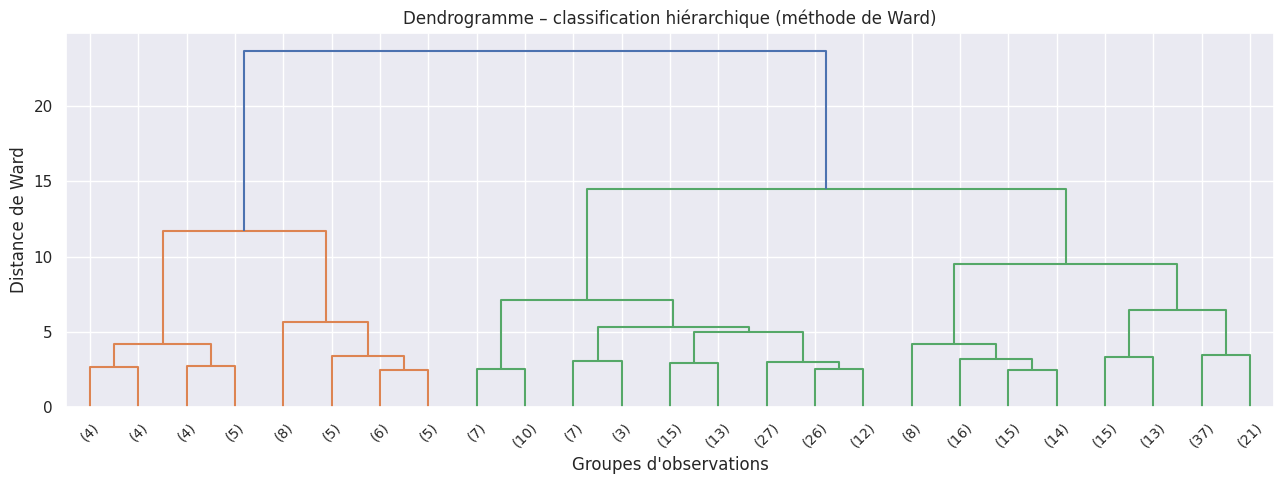

In [73]:
# Dendrogramme calculé sur un échantillon de la période d'entraînement
# pour garder un graphique lisible.
sample_size = min(300, len(X_train_scaled))
sample_for_tree = X_train_scaled[:sample_size]
tree = linkage(sample_for_tree, method="ward")

plt.figure(figsize=(13, 5))
dendrogram(tree, truncate_mode="lastp", p=25)
plt.title("Dendrogramme – classification hiérarchique (méthode de Ward)")
plt.xlabel("Groupes d'observations")
plt.ylabel("Distance de Ward")
plt.tight_layout()
plt.show()


La classification hiérarchique construit progressivement un arbre de regroupements. Le dendrogramme représente les fusions successives : la hauteur indique la distance à laquelle deux groupes sont réunis. La méthode de Ward choisit les fusions qui augmentent le moins l'inertie intra-classe. Le dendrogramme présenté est calculé sur un échantillon de 300 observations au maximum pour rester lisible.

### 17.3 Algorithme 19 – DBSCAN

In [74]:
# DBSCAN repère les zones denses et marque les observations isolées avec -1.
dbscan = DBSCAN(eps=0.7, min_samples=6)
labels_dbscan = dbscan.fit_predict(X_train_scaled)

n_dbscan_clusters = len(set(labels_dbscan) - {-1})
n_dbscan_noise = int(np.sum(labels_dbscan == -1))

print("DBSCAN :")
print("Nombre de clusters (hors bruit) :", n_dbscan_clusters)
print("Nombre de points de bruit :", n_dbscan_noise)
print("Proportion de bruit :", round(n_dbscan_noise / len(labels_dbscan) * 100, 2), "%")


DBSCAN :
Nombre de clusters (hors bruit) : 1
Nombre de points de bruit : 108
Proportion de bruit : 4.55 %


DBSCAN forme des groupes à partir de zones suffisamment denses. Les observations étiquetées `-1` sont considérées comme du bruit : elles ne sont pas suffisamment proches d'un nombre minimal de voisins pour appartenir à un groupe dense. Dans un contexte financier, elles peuvent correspondre à des journées atypiques, mais elles ne doivent pas être automatiquement considérées comme des erreurs.

### 17.4 Algorithme 20 – Mélanges gaussiens

In [75]:
# Modèle probabiliste : chaque observation reçoit une probabilité
# d'appartenir à chacun des trois composants gaussiens.
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42
)
gmm.fit(X_train_scaled)
labels_gmm = gmm.predict(X_train_scaled)
probabilities_gmm = gmm.predict_proba(X_train_scaled)

print("Mélanges gaussiens :")
print("Nombre de clusters :", len(np.unique(labels_gmm)))
print("Score silhouette :", round(silhouette_score(X_train_scaled, labels_gmm), 4))
print("Probabilité maximale moyenne :", round(probabilities_gmm.max(axis=1).mean(), 4))


Mélanges gaussiens :
Nombre de clusters : 3
Score silhouette : 0.2879
Probabilité maximale moyenne : 0.9475


In [76]:
# Exemple des probabilités d'appartenance pour les 10 premières observations.
probability_table = pd.DataFrame(
    probabilities_gmm[:10],
    columns=["Probabilité cluster 0", "Probabilité cluster 1", "Probabilité cluster 2"],
    index=X_train.index[:10]
)
display(probability_table)


,Probabilité cluster 0,Probabilité cluster 1,Probabilité cluster 2
Date,,,
2015-02-02,3.624491e-07,0.999979,0.000021
2015-02-03,3.244659e-02,0.967526,0.000028
2015-02-04,7.432899e-01,0.256704,0.000006
2015-02-05,5.974755e-01,0.402516,0.000009
2015-02-06,7.356382e-01,0.264358,0.000004
2015-02-09,8.678618e-01,0.132136,0.000002
2015-02-10,7.605764e-01,0.239419,0.000005
2015-02-11,8.879282e-01,0.112070,0.000002
2015-02-12,8.721606e-01,0.127835,0.000005


Contrairement à une affectation dure, les mélanges gaussiens donnent une probabilité d'appartenance à chacun des groupes. Une observation peut par exemple appartenir à 70 % au groupe 1 et à 30 % au groupe 2. `n_components=3` fixe le nombre de composantes et `covariance_type="full"` autorise une matrice de covariance complète pour chaque composante.

### 17.5 Tableau comparatif des quatre méthodes

In [77]:
def safe_silhouette(X_values, labels):
    # Le score de silhouette nécessite au moins deux groupes.
    unique_labels = np.unique(labels)
    if len(unique_labels) < 2 or len(unique_labels) >= len(labels):
        return np.nan
    return silhouette_score(
        X_values,
        labels,
        sample_size=min(2000, len(labels)),
        random_state=42
    )

model_labels = {
    "K-Means (17)": labels_kmeans,
    "Hiérarchique (18)": labels_hierarchical,
    "DBSCAN (19)": labels_dbscan,
    "Mélanges gaussiens (20)": labels_gmm
}

comparison_rows = []
for model_name, labels in model_labels.items():
    # Pour DBSCAN, le label -1 désigne le bruit et est exclu
    # du calcul de silhouette des groupes.
    if model_name == "DBSCAN (19)":
        mask = labels != -1
        labels_for_score = labels[mask]
        X_for_score = X_train_scaled[mask]
        cluster_count = len(set(labels) - {-1})
        noise_count = int(np.sum(labels == -1))
    else:
        labels_for_score = labels
        X_for_score = X_train_scaled
        cluster_count = len(np.unique(labels))
        noise_count = 0

    score = safe_silhouette(X_for_score, labels_for_score)
    comparison_rows.append({
        "Algorithme": model_name,
        "Nombre de clusters": cluster_count,
        "Points de bruit": noise_count,
        "Silhouette": score
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)


,Algorithme,Nombre de clusters,Points de bruit,Silhouette
0,K-Means (17),3,0,0.480971
1,Hiérarchique (18),3,0,0.488247
2,DBSCAN (19),1,108,NaN
3,Mélanges gaussiens (20),3,0,0.285066


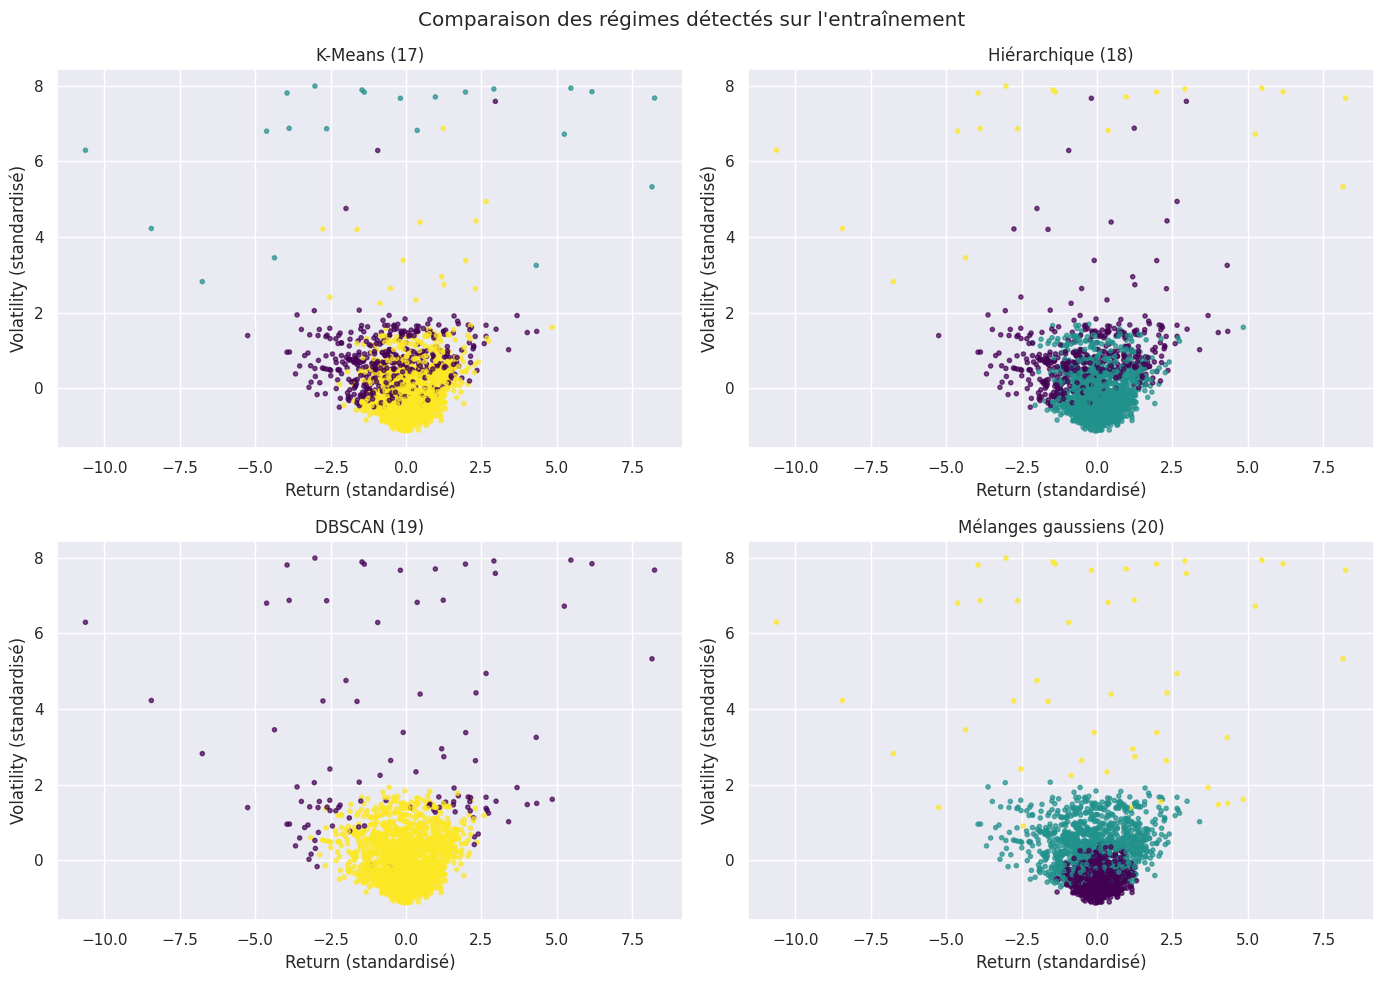

In [78]:
# Visualisation des groupes sur les deux premières variables standardisées.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, (model_name, labels) in zip(axes, model_labels.items()):
    ax.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=9,
        alpha=0.7
    )
    ax.set_title(model_name)
    ax.set_xlabel(features[0] + " (standardisé)")
    ax.set_ylabel(features[1] + " (standardisé)")

plt.suptitle("Comparaison des régimes détectés sur l'entraînement")
plt.tight_layout()
plt.show()


**Interprétation à compléter après exécution :** comparer le nombre de groupes, la quantité de bruit détectée par DBSCAN et les scores de silhouette. Un score plus élevé indique des groupes plus compacts et mieux séparés selon cette métrique, mais ne suffit pas à prouver qu'un découpage représente mieux la réalité économique. Il faut aussi examiner les rendements, la volatilité et la stabilité des groupes.

### 17.6 Affectation de la période de test – méthodes compatibles

In [79]:
# K-Means et GMM peuvent affecter les observations de test
# sans réentraîner les modèles sur cette période.
test_labels_kmeans = kmeans_3.predict(X_test_scaled)
test_labels_gmm = gmm.predict(X_test_scaled)
test_probabilities_gmm = gmm.predict_proba(X_test_scaled)

print("Test - K-Means :", len(test_labels_kmeans), "observations affectées")
print("Test - GMM :", len(test_labels_gmm), "observations affectées")
print("GMM - probabilité maximale moyenne sur le test :",
      round(test_probabilities_gmm.max(axis=1).mean(), 4))

# Pas de prédiction directe standard pour AgglomerativeClustering et DBSCAN.
print("Rappel : AgglomerativeClustering et DBSCAN ne proposent pas predict() standard.")


Test - K-Means : 594 observations affectées
Test - GMM : 594 observations affectées
GMM - probabilité maximale moyenne sur le test : 0.9361
Rappel : AgglomerativeClustering et DBSCAN ne proposent pas predict() standard.


Pour éviter une fuite d'information, les quatre modèles sont ajustés sur l'entraînement uniquement. Les modèles K-Means et GMM affectent ensuite le jeu de test avec `predict`. Pour la classification hiérarchique et DBSCAN, scikit-learn ne fournit pas de prédiction directe standard pour de nouvelles observations ; leurs résultats sont donc interprétés comme une découverte de groupes sur la période d'entraînement. Une méthode d'affectation complémentaire devrait être définie avant de les utiliser en production.

## 18.Conclusion de l'analyse comparative des algorithmes de clustering

Dans ce projet, nous avons appliqué quatre algorithmes de clustering afin d'identifier des groupes d'observations dans les données financières : K-Means, la classification hiérarchique ascendante, DBSCAN et les mélanges gaussiens (GMM).

Les résultats obtenus montrent des différences de comportement entre les méthodes.

K-Means a permis de former trois clusters avec un score de silhouette de 0,39, indiquant une séparation modérée entre les groupes.

La classification hiérarchique ascendante, utilisant la méthode de Ward, a obtenu un score de silhouette de 0,4782. Il s'agit du meilleur score obtenu parmi les méthodes évaluées avec cet indicateur. Elle semble donc offrir une meilleure séparation des groupes sur les données étudiées.

DBSCAN a identifié un seul cluster et 108 observations considérées comme du bruit. Ce résultat montre que les paramètres utilisés ne permettent pas de détecter plusieurs zones denses dans les données.

Enfin, le modèle GMM a affecté 594 observations et obtenu une probabilité maximale moyenne de 93,61 % sur les données de test, ce qui indique une forte confiance moyenne dans ses affectations.

En conclusion, la classification hiérarchique apparaît comme la méthode la plus intéressante selon le score de silhouette obtenu. Cependant, le choix final doit également prendre en compte l'interprétabilité des groupes, leur stabilité et leur pertinence dans le contexte financier.

Cette comparaison montre l'intérêt d'utiliser plusieurs algorithmes afin de mieux comprendre la structure des données financières.

In [80]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
